In [ ]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt

# ==========================================
# 1. Load and Clean the Data
# ==========================================
# Load the dataset
df = pd.read_csv('/Users/timothyconsidine/Desktop/School/Spring 2026/Machine Learning/Project/PRSA_data_2010.1.1-2014.12.31.csv')

# Combine year, month, day, and hour into a proper datetime index
df['datetime'] = pd.to_datetime(df[['year', 'month', 'day', 'hour']])
df = df.set_index('datetime')

# Drop the original time columns and the 'No' index column
df = df.drop(columns=['No', 'year', 'month', 'day', 'hour'])

# Handle missing PM2.5 values using forward fill, then backward fill 
# (Air quality changes gradually, so the previous hour's value is a safe estimate)
df['pm2.5'] = df['pm2.5'].ffill().bfill()

# One-hot encode the categorical wind direction ('cbwd')
df = pd.get_dummies(df, columns=['cbwd'], drop_first=True, dtype=float)
print(df)

# ==========================================
# 2. Feature Engineering (Lag Features)
# ==========================================
# We want to predict current PM2.5 using past PM2.5 values.
#df['pm2.5_lag_1hr'] = df['pm2.5'].shift(1)   # What was PM2.5 one hour ago?
df['pm2.5_lag_24hr'] = df['pm2.5'].shift(24) # What was PM2.5 at this time yesterday?

# Drop the first 24 rows since they will have missing values from the shift
df = df.dropna()

# ==========================================
# 3. Chronological Train-Test Split
# ==========================================
# Train on 2010-2013, Test on 2014 to avoid data leakage
train = df[df.index < '2014-01-01']
test = df[df.index >= '2014-01-01']

# Separate features (X) and target (y)
X_train = train.drop(columns=['pm2.5'])
y_train = train['pm2.5']
X_test = test.drop(columns=['pm2.5'])
y_test = test['pm2.5']
######################################################################<HERE
# ==========================================
# 4. Model Training
# ==========================================
# Initialize and train the Random Forest
# n_jobs=-1 uses all available CPU cores to speed up training
rf_model = RandomForestRegressor(n_estimators=300, max_features=0.3,random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

# ==========================================
# 5. Evaluation and Metrics
# ==========================================
# Generate predictions on the 2014 test set
predictions = rf_model.predict(X_test)

# Calculate metrics
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))

print("\n--- Model Performance ---")
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")

In [ ]:
lags = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 0]

maes = []

for lag in lags:
    mae = run_mlr(lag)
    maes.append(mae)

print(maes)

In [ ]:
# ==========================================
# 6. Feature Importance Visualization
# ==========================================
# Extract feature importances to see what the model relied on most
importances = rf_model.feature_importances_
features = X_train.columns
indices = np.argsort(importances)[:] # Grab the top 10 features

plt.figure(figsize=(10, 6))
plt.barh(range(len(indices)), importances[indices], align='center')
plt.yticks(range(len(indices)), [features[i] for i in indices])
plt.xlabel('Relative Importance')
plt.title('Feature Importances for PM2.5 Prediction')
plt.tight_layout()

#Saving figure 
plt.savefig('/Users/timothyconsidine/Desktop/School/Spring 2026/Machine Learning/Project/feature_importance.png')
plt.show()

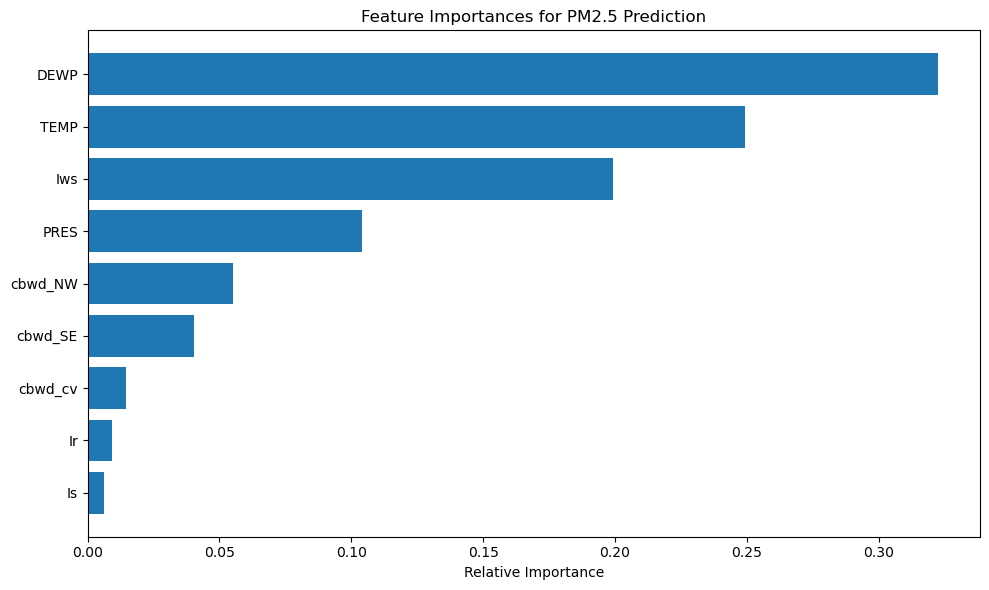

In [9]:
# ==========================================
# 6. Feature Importance Visualization
# ==========================================
# Extract feature importances to see what the model relied on most
best_rf = rf_model.best_estimator_
importances = best_rf.feature_importances_
features = X_train.columns
indices = np.argsort(importances)[:] # Grab the top 10 features

plt.figure(figsize=(10, 6))
plt.barh(range(len(indices)), importances[indices], align='center')
plt.yticks(range(len(indices)), [features[i] for i in indices])
plt.xlabel('Relative Importance')
plt.title('Feature Importances for PM2.5 Prediction')
plt.tight_layout()

#Saving figure 
plt.savefig('/Users/timothyconsidine/Desktop/School/Spring 2026/Machine Learning/Project/feature_importance.png')
plt.show()

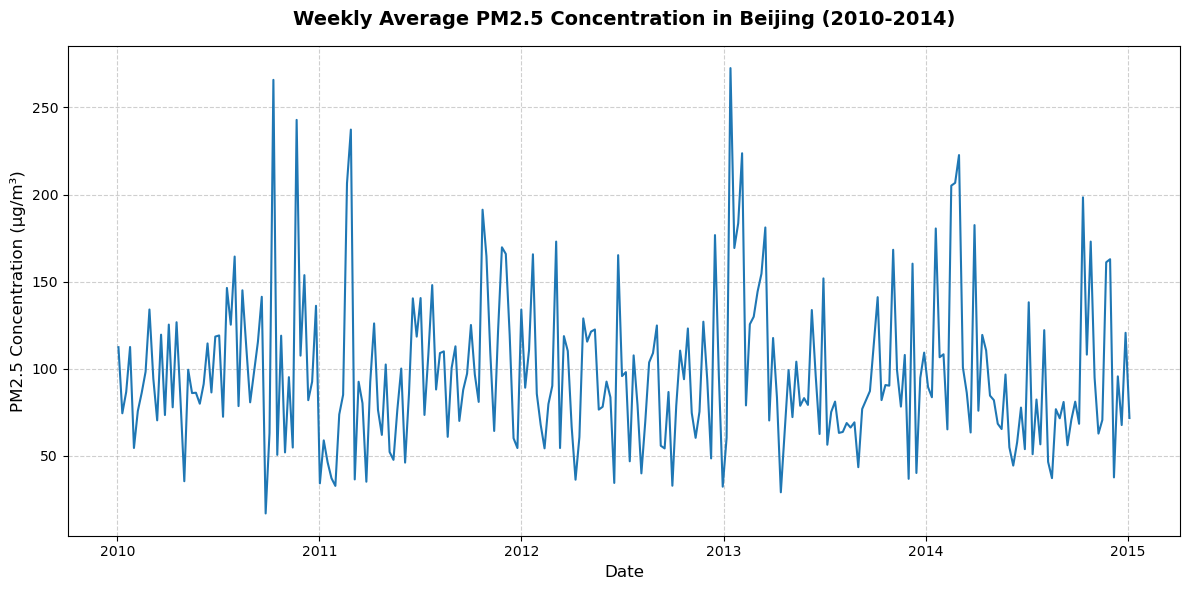

In [8]:
import matplotlib.pyplot as plt

# 1. Resample the data
# 'W' stands for weekly. You could also use 'M' for monthly.
# We calculate the mean for each week to smooth out the noise.
weekly_pm25 = df['pm2.5'].resample('W').mean()

# 2. Set up the figure size (wide and relatively short is best for time series)
plt.figure(figsize=(12, 6))

# 3. Plot the data
plt.plot(weekly_pm25.index, weekly_pm25.values, color='#1f77b4', linewidth=1.5)

# 4. Format the chart for your paper
plt.title('Weekly Average PM2.5 Concentration in Beijing (2010-2014)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Date', fontsize=12)
plt.ylabel('PM2.5 Concentration (µg/m³)', fontsize=12)

# Add a subtle grid to make it easier to read values
plt.grid(True, linestyle='--', alpha=0.6)

# Ensure everything fits within the figure boundaries without getting cut off
plt.tight_layout()

#Save figure
plt.savefig('/Users/timothyconsidine/Desktop/School/Spring 2026/Machine Learning/Project/PM2.5_W_Avg.png')

# 5. Display the plot
plt.show()

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


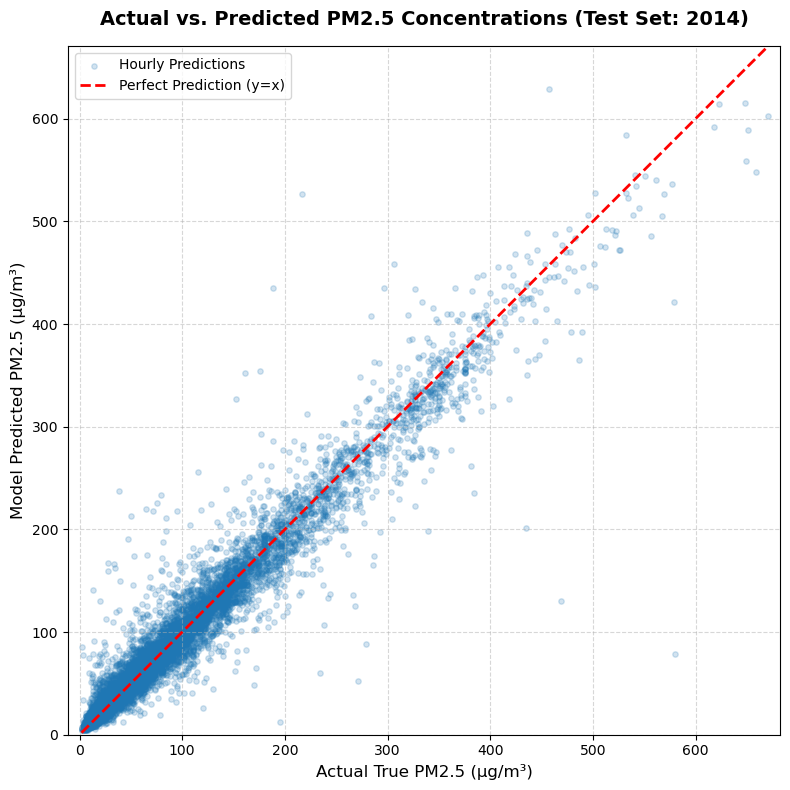

In [10]:
import matplotlib.pyplot as plt
import numpy as np

# Set up a square figure (square is best for y=x reference lines)
plt.figure(figsize=(8, 8))

# 1. Plot the scatter points
# alpha=0.2 makes the dots transparent. Darker areas mean more overlapping points.
plt.scatter(y_test, predictions, alpha=0.2, color='#1f77b4', s=15, label='Hourly Predictions')

# 2. Find the minimum and maximum values to scale the axes perfectly
max_val = max(y_test.max(), predictions.max())
min_val = min(y_test.min(), predictions.min())

# 3. Draw the y=x reference line (the "Perfect Prediction" line)
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Perfect Prediction (y=x)')

# 4. Format the chart for your paper
plt.title('Actual vs. Predicted PM2.5 Concentrations (Test Set: 2014)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Actual True PM2.5 (µg/m³)', fontsize=12)
plt.ylabel('Model Predicted PM2.5 (µg/m³)', fontsize=12)
plt.legend(loc='upper left')

# Add a subtle grid
plt.grid(True, linestyle='--', alpha=0.5)

# Force the axes to be identical so the diagonal line is a true 45 degrees
plt.axis('equal')
plt.xlim(0, max_val)
plt.ylim(0, max_val)

plt.tight_layout()
plt.show()

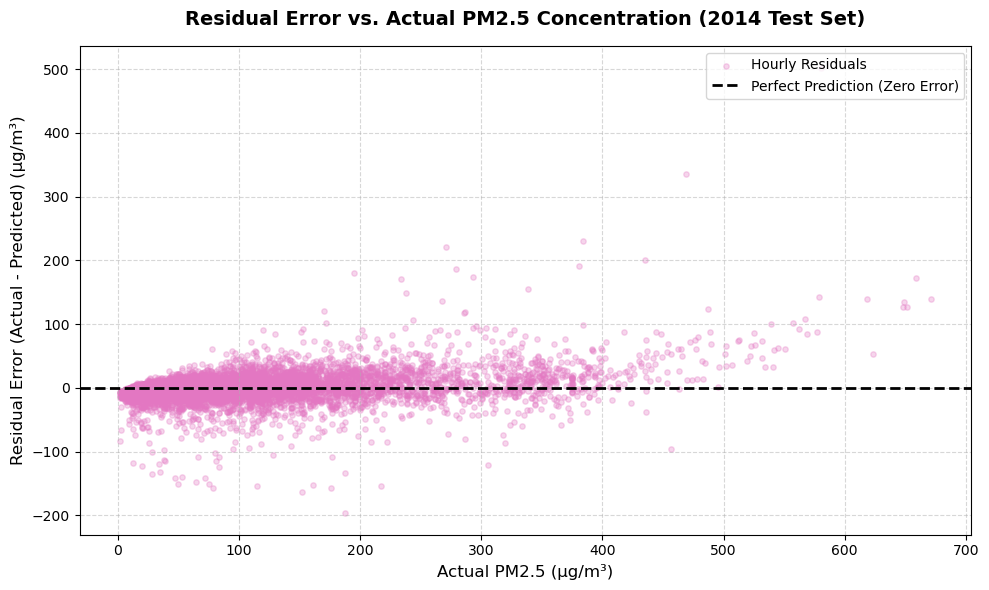

In [8]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Calculate the raw residuals
# Positive value = Model under-predicted the pollution
# Negative value = Model over-predicted the pollution
residuals = y_test - predictions

# 2. Set up the figure
plt.figure(figsize=(10, 6))

# 3. Plot the scatter points
# Using alpha=0.3 to handle the density of the 8,760 hourly points
plt.scatter(y_test, residuals, alpha=0.3, color='#e377c2', s=15, label='Hourly Residuals')

# 4. Draw the horizontal zero-error baseline
plt.axhline(0, color='black', linestyle='--', linewidth=2, label='Perfect Prediction (Zero Error)')

# 5. Format the chart for your paper
plt.title('Residual Error vs. Actual PM2.5 Concentration (2014 Test Set)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Actual PM2.5 (µg/m³)', fontsize=12)
plt.ylabel('Residual Error (Actual - Predicted) (µg/m³)', fontsize=12)

# 6. Add legend and grid
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()

#Saving plot
plt.savefig('/Users/timothyconsidine/Desktop/School/Spring 2026/Machine Learning/Project/residual_error.png')
plt.show()

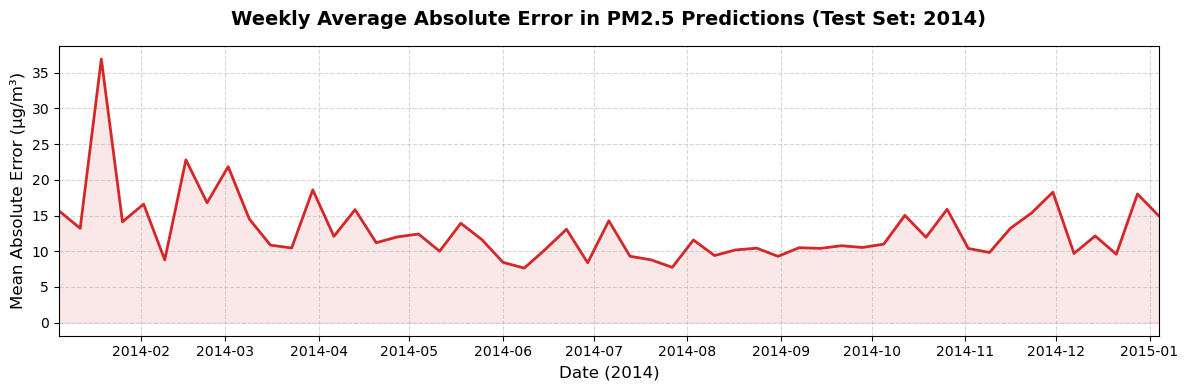

In [14]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Calculate the absolute error for every single hour
# (Actual PM2.5 minus Predicted PM2.5, ignoring the negative/positive direction)
absolute_errors = np.abs(y_test - predictions)

# 2. Resample the errors to a weekly average
# 'W' stands for weekly. This averages the ~168 hours in each week into a single point.
weekly_errors = absolute_errors.resample('W').mean()

# 3. Set up the figure (Wide and relatively short is the standard for time series)
plt.figure(figsize=(12, 4))

# 4. Plot the data
plt.plot(weekly_errors.index, weekly_errors.values, color='#d62728', linewidth=2)

# Fill the area under the line to make the seasonal volume of error visually striking
plt.fill_between(weekly_errors.index, weekly_errors.values, color='#d62728', alpha=0.1)

# 5. Format the chart for your paper
plt.title('Weekly Average Absolute Error in PM2.5 Predictions (Test Set: 2014)', 
          fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Date (2014)', fontsize=12)
plt.ylabel('Mean Absolute Error (µg/m³)', fontsize=12)

# Add a subtle grid to help the reader estimate the error values at different months
plt.grid(True, linestyle='--', alpha=0.5)

# Ensure the x-axis limits fit the data perfectly without awkward white space at the edges
plt.xlim(weekly_errors.index.min(), weekly_errors.index.max())

plt.tight_layout()

#Saving plot
plt.savefig('/Users/timothyconsidine/Desktop/School/Spring 2026/Machine Learning/Project/w_avg_error.png')
plt.show()


--- Model Performance ---
Mean Absolute Error (MAE): 47.04
Root Mean Squared Error (RMSE): 67.72


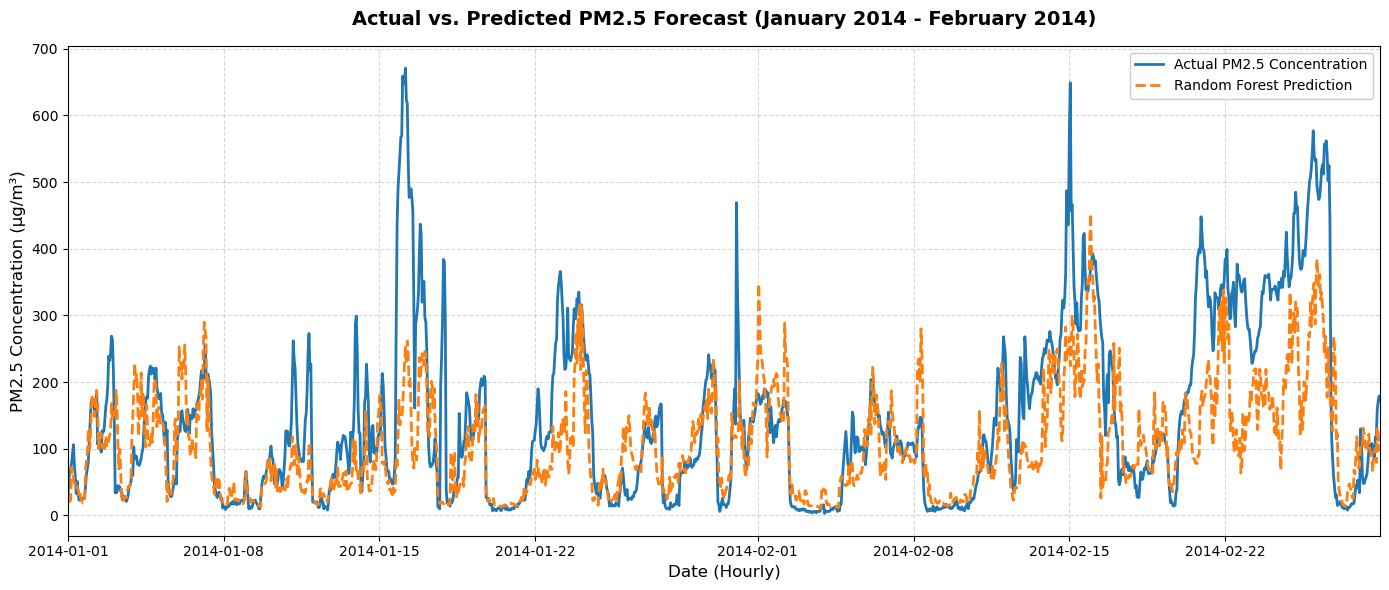

In [29]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Slice out a specific time window for clarity (e.g., February 2014)
# Since your index is already a datetime object, pandas makes this incredibly easy
zoom_start = '2014-01-01'
zoom_end = '2014-02-28'

actual_zoomed = y_test[zoom_start:zoom_end]
predicted_zoomed = pd.Series(predictions, index=y_test.index)[zoom_start:zoom_end]

# 2. Set up a wide figure
plt.figure(figsize=(14, 6))

# 3. Plot the Actual PM2.5 (Solid, thick, dark line to represent reality)
plt.plot(actual_zoomed.index, actual_zoomed.values, 
         color='#1f77b4', linewidth=2, label='Actual PM2.5 Concentration')

# 4. Plot the Model's Predictions (Dashed, bright line to represent the forecast)
plt.plot(predicted_zoomed.index, predicted_zoomed.values, 
         color='#ff7f0e', linewidth=2, linestyle='--', label='Random Forest Prediction')

# 5. Format the chart for your paper
plt.title('Actual vs. Predicted PM2.5 Forecast (January 2014 - February 2014)', 
          fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Date (Hourly)', fontsize=12)
plt.ylabel('PM2.5 Concentration (µg/m³)', fontsize=12)

# 6. Add legend and styling
plt.legend(loc='upper right', framealpha=1.0)
plt.grid(True, linestyle='--', alpha=0.5)

# Ensure the x-axis fits snugly against the data
plt.xlim(actual_zoomed.index.min(), actual_zoomed.index.max())

# Calculate metrics
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))

print("\n--- Model Performance ---")
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")

plt.tight_layout()

#Saving plot
plt.savefig('/Users/timothyconsidine/Desktop/School/Spring 2026/Machine Learning/Project/model_vs_data')
plt.show()